In [38]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

# 1. Bank Marketing datasetini yükləyirik
# Dataset sep=';' ilə ayrılıb
df = pd.read_csv("../data/raw/bank-full.csv", sep=";")

# Target: 'y' -> 'yes' (1) / 'no' (0)
y = (df['y'] == 'yes').astype(int)
X_raw = df.drop(columns=['y'])


In [39]:
# pdays: -1 = əvvəl əlaqə olmayıb (kodlaşdırılmış işarədir, real gün sayı deyil)
df['previously_contacted'] = (df['pdays'] != -1).astype(int)

# real pdays dəyərləri 1-dən başlayır, ona görə 0 istifadə edilməyən dəyərdir
df['pdays_clean'] = df['pdays'].replace(-1, 0)

# X_raw-ı yeni sütunlarla yenidən təyin et
X_raw = df.drop(columns=['y'])

In [40]:
# Sütun tipləri
num_cols_with_duration = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays_clean', 'previous']
num_cols_clean = ['age', 'balance', 'day', 'campaign', 'pdays_clean', 'previous']

cat_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
            'month', 'poutcome', 'previously_contacted']

# Pipeline Yaradan Funksiya
def make_bank_pipeline(numeric_features):
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numeric_features),
            ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), cat_cols)
        ]
    )
    return Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(max_iter=1000, random_state=42))
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# A) SİZMA İLƏ (duration daxil)
pipe_with_leakage = make_bank_pipeline(num_cols_with_duration)
cv_leakage = cross_validate(pipe_with_leakage, X_raw, y, cv=cv, scoring='roc_auc')

# B) SİZMASIZ (duration çıxarılıb - REAL MODEL)
pipe_clean = make_bank_pipeline(num_cols_clean)
X_clean = X_raw.drop(columns=['duration', 'pdays'])
cv_clean = cross_validate(pipe_clean, X_clean, y, cv=cv, scoring='roc_auc')

# cross_validate(..., scoring='roc_auc') istifadə etdikdə nəticələr 'test_score' daxilində olur:
print("=== DATA LEAKAGE DIAQNOSTİKASI ===")
print(f"duration İLƏ (Şişirdilmiş AUC)  : {np.mean(cv_leakage['test_score']):.4f} ± {np.std(cv_leakage['test_score']):.4f}")
print(f"duration SIZ (Təmiz Real AUC)   : {np.mean(cv_clean['test_score']):.4f} ± {np.std(cv_clean['test_score']):.4f}")

=== DATA LEAKAGE DIAQNOSTİKASI ===
duration İLƏ (Şişirdilmiş AUC)  : 0.9066 ± 0.0050
duration SIZ (Təmiz Real AUC)   : 0.7655 ± 0.0084


In [41]:
from sklearn.model_selection import cross_val_predict

# Sızmasız təmiz pipeline ilə out-of-fold proqnozlar
y_proba_oof = cross_val_predict(pipe_clean, X_clean, y, cv=cv, method="predict_proba")[:, 1]

# Nəticələri DataFrame-ə yığırıq və azalan sırayla sıralayırıq
df_bank = pd.DataFrame({'y_true': y, 'y_proba': y_proba_oof})
df_bank = df_bank.sort_values(by='y_proba', ascending=False).reset_index(drop=True)

N = len(df_bank) # 45,211 müştəri
k_10 = int(0.10 * N) # Top 10% -> ~4,521 müştəri

total_conversions = df_bank['y_true'].sum() # Toplam əmanət açanlar (~5,289)
base_conversion_rate = df_bank['y_true'].mean() # Baza dönüşüm nisbəti (~11.7%)

# Top 10%-də tutulan müştəri sayı
top_10_conversions = df_bank.iloc[:k_10]['y_true'].sum()

precision_10 = top_10_conversions / k_10
recall_10 = top_10_conversions / total_conversions
lift_10 = precision_10 / base_conversion_rate

print("\n=== BANK PROPENSITY: TOP 10% ZƏNG SİYAHISI ===")
print(f"Zəng ediləcək müştəri sayı (k) : {k_10}")
print(f"Tutulan Real Əmanət Sayı      : {top_10_conversions} / {total_conversions}")
print(f"Precision@10%                  : {precision_10:.4f} (Zəng olunacaq 4,521 nəfərin {precision_10*100:.1f}%-i əmanət açacaq)")
print(f"Recall@10%                     : {recall_10:.4f} (Bütün əmanət açanların {recall_10*100:.1f}%-i bu 10%-ə düşdü)")
print(f"Lift@10%                       : {lift_10:.2f}x (Təsadüfi zəngdən {lift_10:.2f} dəfə daha effektivdir)")


=== BANK PROPENSITY: TOP 10% ZƏNG SİYAHISI ===
Zəng ediləcək müştəri sayı (k) : 4521
Tutulan Real Əmanət Sayı      : 2177 / 5289
Precision@10%                  : 0.4815 (Zəng olunacaq 4,521 nəfərin 48.2%-i əmanət açacaq)
Recall@10%                     : 0.4116 (Bütün əmanət açanların 41.2%-i bu 10%-ə düşdü)
Lift@10%                       : 4.12x (Təsadüfi zəngdən 4.12 dəfə daha effektivdir)


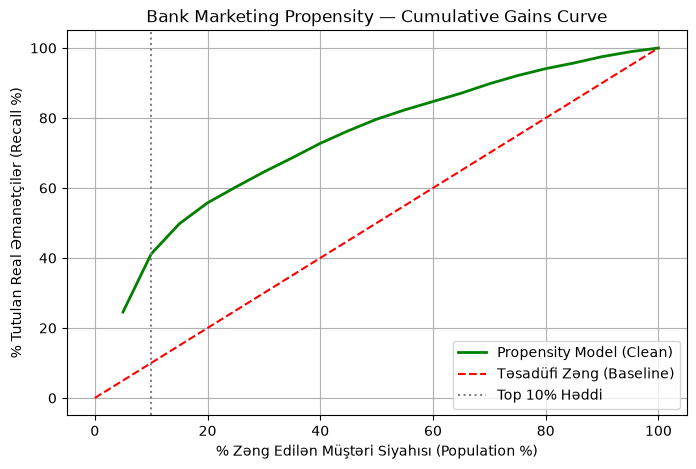

In [42]:
import matplotlib.pyplot as plt

percentages = np.linspace(0.05, 1.0, 20)
recalls = []

for p in percentages:
    k = int(p * N)
    rec = df_bank.iloc[:k]['y_true'].sum() / total_conversions
    recalls.append(rec)

plt.figure(figsize=(8, 5))
plt.plot(percentages * 100, np.array(recalls) * 100, label='Propensity Model (Clean)', color='green', lw=2)
plt.plot([0, 100], [0, 100], label='Təsadüfi Zəng (Baseline)', color='red', linestyle='--')
plt.axvline(x=10, color='gray', linestyle=':', label='Top 10% Həddi')
plt.xlabel('% Zəng Edilən Müştəri Siyahısı (Population %)')
plt.ylabel('% Tutulan Real Əmanətçilər (Recall %)')
plt.title('Bank Marketing Propensity — Cumulative Gains Curve')
plt.legend()
plt.grid(True)
import os
os.makedirs("../reports/figures", exist_ok=True)
plt.savefig("../reports/figures/bank_gains_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [43]:
print((df['pdays'] == -1).sum(), "müştəri heç vaxt əvvəl əlaqə olmayıb")

36954 müştəri heç vaxt əvvəl əlaqə olmayıb


In [44]:
print(df['pdays'].describe())

count    45211.000000
mean        40.197828
std        100.128746
min         -1.000000
25%         -1.000000
50%         -1.000000
75%         -1.000000
max        871.000000
Name: pdays, dtype: float64


In [45]:
cv_clean2 = cross_validate(pipe_clean, X_clean, y, cv=cv,
                           scoring=['roc_auc', 'average_precision'])

print(f"ROC-AUC: {cv_clean2['test_roc_auc'].mean():.4f} ± {cv_clean2['test_roc_auc'].std():.4f}")
print(f"AP     : {cv_clean2['test_average_precision'].mean():.4f} ± {cv_clean2['test_average_precision'].std():.4f}")

ROC-AUC: 0.7655 ± 0.0084
AP     : 0.4055 ± 0.0162


In [46]:
pd.crosstab(df['pdays'] == -1, df['poutcome'])

poutcome,failure,other,success,unknown
pdays,,,,
False,4901,1840,1511,5
True,0,0,0,36954


In [47]:
print(X_clean.columns.tolist())
print("pdays_clean var:", 'pdays_clean' in X_clean.columns)
print("previously_contacted var:", 'previously_contacted' in X_clean.columns)
print("pdays (köhnə) var:", 'pdays' in X_clean.columns)

['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'previous', 'poutcome', 'previously_contacted', 'pdays_clean']
pdays_clean var: True
previously_contacted var: True
pdays (köhnə) var: False


In [48]:
pipe_clean.fit(X_clean, y)
names = pipe_clean.named_steps['preprocessor'].get_feature_names_out()
coefs = pipe_clean.named_steps['classifier'].coef_[0]
for n, c in zip(names, coefs):
    if 'pdays' in n or 'previously' in n:
        print(f"{n:35s} {c:+.3f}")

num__pdays_clean                    -0.006
cat__previously_contacted_1         -0.446


# ## Nəticələr (Faza 6)

**Leakage.** `duration` zəng bitəndən sonra məlum olur və nəticənin özünün təzahürüdür. Onunla ROC-AUC 0.9066, onsuz 0.7655 çıxır. 0.14 fərq real istifadədə əldə olunmayacaq məlumatdan gəlir, ona görə model `duration` olmadan qurulub.

**pdays kodlaşdırması.** 36,954 müştəri (81.7%) əvvəl heç vaxt əlaqə olmayıb, bu sətirlərdə `pdays = -1`. Bu, real gün sayı deyil, işarədir. Ona görə iki sütun yaradıldı: `previously_contacted` (0/1) və `pdays_clean` (`-1` → 0). Düzəliş AUC-ni dəyişmədi (0.7655 ± 0.0084), çünki `poutcome = unknown` eyni informasiyanı daşıyır.

**Nəticələr (5-fold stratified CV, duration və köhnə pdays çıxarılıb).**
- ROC-AUC: 0.7655 ± 0.0084
- AP: 0.4055 ± 0.0162 (baza 0.117)

**Top 10% zəng siyahısı (4521 müştəri).** 2177 əmanət açan tutuldu (5289-dan). Precision 0.4815, recall 0.4116, lift 4.12×.

**Telco ilə müqayisə.** Bank-da lift (4.12×) Telco-dan (2.78×) yüksəkdir, amma bu, baza nisbətinin (11.7% vs 26.5%) aşağı olmasından gəlir. Sıralama keyfiyyəti (AUC 0.77 vs 0.84) Telco-da yüksəkdir. Buna görə lift tək başına modelin üstünlüyünü göstərmir.

**Məhdudiyyət.** Bu model propensity modelidir, uplift deyil. Yüksək ehtimallı müştərilərin bir hissəsi zəng olmadan da əmanət açacaq ("sure things"). Əsl təsiri ölçmək üçün zəng edilən və edilməyən qruplar üzərində A/B test lazımdır.